# OCN-BC: KMT

Corresponding Author: Feng Zhu (fengzhu@ucar.edu)

- Objective: generate the POP bathymetry (KMT), region mask, and SCRIP files for the MioMIP2 Phase 2 CORE experiment (15 Ma),
  by remapping the MioMIP2 paleogeography onto the standard `gx1v6` POP grid, with clean-up steps.
- Workflow (following [`create_eocene_bathy_w_grid.ipynb`](../../../Eocene/DeepMIP2/notebooks/create_eocene_bathy_w_grid.ipynb) by Jiang Zhu):
  1. Inspect the raw MioMIP2 paleogeography and build the cell edges xESMF needs for conservative remapping.
  2. Define the helper functions.
  3. Read the POP gx1v6 grid data.
  4. Conservatively remap bathymetry onto the POP grid and convert depth to KMT.
  5. Clean up KMT (boundary walls, ocean-fraction coastline, isolated points, islands, disconnected bays, channels, minimum depth, etc).
  6. Build the region mask.
  7. Save the binary KMT and region mask, a netCDF copy, and the SCRIP file.
- Notes
  - The POP horizontal grid is unchanged (standard `gx1v6`); only KMT, region mask, and SCRIP grid files are created.
  - POP is on an Arakawa B-grid: a U point is active only if all four surrounding T cells are wet,
    so a channel one T-cell wide carries no flow. That is why isolated points are removed rather than left as deep dead ends.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.chdir('/glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Miocene/MioMIP2/notebooks')
import sys
import time
from pathlib import Path
from collections import deque

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import ndimage
import xesmf

import x4c  # optional: for better visualization
x4c.set_style('journal', font_scale=1.2)

# `utils/` sits at the repo root, four levels up from this notebook.
sys.path.append('../../../../utils/')
from Plot_2D import Plot_2D

case = 'MioMIP2_Phase2_CORE'
raw_topo_fpath = f'../data/{case}_paleogeography.nc'
scripgrid_dpath = '/glade/p/cesmdata/inputdata/share/scripgrids'

today = '260903' 

## 1. Load the raw paleogeography

- Raw paleogeography for the MioMIP2 Phase 2 CORE experiment (15 Ma, Zahirovic et al., 2022 reconstruction)
- Remove the duplicate seam at 180E and add cell edges (used only for conservative remapping)

In [2]:
ds_topo_raw = xr.open_dataset(raw_topo_fpath)

# drop duplicate seam: lon spans -180 to 180
ds_topo_raw = ds_topo_raw.isel(lon=slice(0, -1))

# Add cell edges, used only for conservative remapping
lat = ds_topo_raw.lat
lon = ds_topo_raw.lon
dlat = (lat[1] - lat[0]) / 2   # half a cell
dlon = (lon[1] - lon[0]) / 2

# clip so the polar cells stop at the pole instead of wrapping past it
ds_topo_raw['lat_b'] = ('lat_b', np.clip(np.hstack([lat - dlat, lat[-1] + dlat]), -90, 90))
ds_topo_raw['lon_b'] = ('lon_b', np.hstack([lon - dlon, lon[-1] + dlon]))
ds_topo_raw

<xarray.Dataset> Size: 12MB
Dimensions:             (lat: 721, lon: 1440, lat_b: 722, lon_b: 1441)
Coordinates:
  * lat                 (lat) float64 6kB -90.0 -89.75 -89.5 ... 89.5 89.75 90.0
  * lon                 (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
  * lat_b               (lat_b) float64 6kB -90.0 -89.88 -89.62 ... 89.88 90.0
  * lon_b               (lon_b) float64 12kB -180.1 -179.9 ... 179.6 179.9
Data variables:
    topo                (lat, lon) float32 4MB ...
    landmask            (lat, lon) float32 4MB ...
    icesheet_thickness  (lat, lon) float32 4MB ...
Attributes:
    Conventions:  CF-1.7
    title:        Paleogeography boundary condition for the MioMIP2 Phase 2 C...
    history:      
    description:  Reconstruction is at 15 Ma using the Zahirovic et al. (2022...
    GMT_version:  6.6.0 [MP]

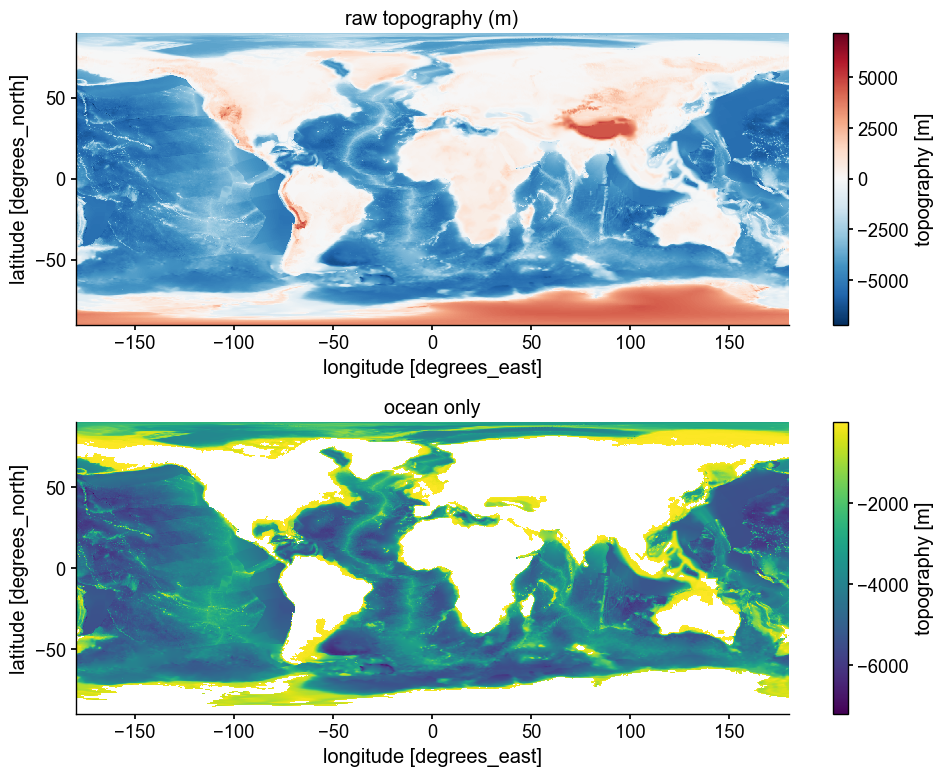

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 8))
ds_topo_raw.topo.plot(ax=ax[0])
ds_topo_raw.topo.where(ds_topo_raw.topo < 0).plot(ax=ax[1])
ax[0].set_title('raw topography (m)')
ax[1].set_title('ocean only')
fig.tight_layout()

## 2. Helper functions

Adapted from [`create_eocene_bathy_w_grid.ipynb`](../../../Eocene/DeepMIP2/notebooks/create_eocene_bathy_w_grid.ipynb);
`plot3` is rewritten with matplotlib.

In [4]:
def read_pop_grid(grid_file, depth_file, nlat, nlon):
    """POP grid Dataset from a POP horiz grid binary and a vertical grid file.

    Corners per cell counterclockwise from SW, centers from the corner mean in 3D, bottom row handled its way.
    Returns the Dataset plus corner_lat, corner_lon, TLAT, TLONG in radians for
    to_scrip.
    """
    # 7 records of nlat*nlon float64, big-endian.  ULAT/ULONG are radians at U
    # points, HTN/HTE are T-cell edge lengths in cm.
    rec = np.fromfile(grid_file, dtype=">f8").reshape(7, nlat, nlon).astype(float)
    ULAT, ULONG, HTN, HTE = rec[0], rec[1], rec[2], rec[3]

    # corners SW, SE, NE, NW.  U[j,i] is the NE corner of T[j,i]; NW is the
    # column to the west (cyclic); the southern pair comes from the row below
    lat = np.empty((nlat, nlon, 4))
    lon = np.empty((nlat, nlon, 4))
    lat[:, :, 2], lon[:, :, 2] = ULAT, ULONG                           # NE
    lat[:, :, 3] = np.roll(ULAT, 1, axis=1)                            # NW
    lon[:, :, 3] = np.roll(ULONG, 1, axis=1)
    lat[1:, :, 0], lon[1:, :, 0] = lat[:-1, :, 3], lon[:-1, :, 3]      # SW
    lat[1:, :, 1], lon[1:, :, 1] = lat[:-1, :, 2], lon[:-1, :, 2]      # SE
    for c in (0, 1):    # bottom row: extrapolate lat, clamp at the pole; lon
        lat[0, :, c] = np.maximum(lat[1, :, c] - (lat[2, :, c] - lat[1, :, c]), -np.pi / 2)
        lon[0, :, c] = lon[0, :, 3 - c]     # copied from the northern corner

    # keep each cell's corners within 3*pi/2 of the previous one
    lon %= 2 * np.pi
    for k in range(1, 4):
        d = lon[:, :, k] - lon[:, :, k - 1]
        lon[:, :, k] -= 2 * np.pi * ((d > 1.5 * np.pi).astype(float) - (d < -1.5 * np.pi))

    # centers: mean of the four corners as 3D unit vectors
    x = (np.cos(lon) * np.cos(lat)).mean(axis=2)
    y = (np.sin(lon) * np.cos(lat)).mean(axis=2)
    z = np.sin(lat).mean(axis=2)
    TLAT = np.arcsin(z / np.sqrt(x * x + y * y + z * z))
    TLONG = np.arctan2(y, x)
    TLAT[0] = 2 * TLAT[1] - TLAT[2]        # row 0: lat extrapolated, lon copied
    TLONG[0] = TLONG[1]
    TLONG %= 2 * np.pi

    DXT = 0.5 * (HTN + np.roll(HTN, 1, axis=0))
    DXT[0] = HTN[0]
    DYT = 0.5 * (HTE + np.roll(HTE, 1, axis=1))

    # xESMF wants shared corners, (nlat+1, nlon+1)
    lat_b = np.empty((nlat + 1, nlon + 1))
    lon_b = np.empty((nlat + 1, nlon + 1))
    lat_b[:-1, :-1], lon_b[:-1, :-1] = lat[:, :, 0], lon[:, :, 0]      # SW
    lat_b[:-1, -1], lon_b[:-1, -1] = lat[:, -1, 1], lon[:, -1, 1]      # SE
    lat_b[-1, :-1], lon_b[-1, :-1] = lat[-1, :, 3], lon[-1, :, 3]      # NW
    lat_b[-1, -1], lon_b[-1, -1] = lat[-1, -1, 2], lon[-1, -1, 2]      # NE

    dz = np.loadtxt(depth_file)[:, 0]      # cm
    z_w_bot = np.cumsum(dz)

    xy, xyb = ("nlat", "nlon"), ("nlat_b", "nlon_b")
    ds = xr.Dataset(
        {"HTN": (xy, HTN), "HTE": (xy, HTE), "DXT": (xy, DXT), "DYT": (xy, DYT),
         "TAREA": (xy, DXT * DYT),
         "lat_b": (xyb, np.degrees(lat_b)), "lon_b": (xyb, np.degrees(lon_b) % 360.0)},
        coords={"TLAT": (xy, np.degrees(TLAT)), "TLONG": (xy, np.degrees(TLONG)),
                "ULAT": (xy, np.degrees(ULAT)), "ULONG": (xy, np.degrees(ULONG) % 360.0),
                "z_t": ("z_t", z_w_bot - 0.5 * dz), "z_w_bot": ("z_w_bot", z_w_bot),
                "dz": ("z_t", dz)},
    )
    return ds, lat, lon, TLAT, TLONG


# remap

def remap_topo(ds_topo, ds_pop_grid, varname="topo", weights=None, reuse=False,
               method="conservative"):
    """Remap topography (m, positive up) onto the POP grid.

    Returns a Dataset with topo (cm, positive down) and ofrac (ocean fraction).
    Depth is the whole-cell mean with land counted as zero, which conserves
    ocean volume.  No land mask is applied -- threshold ofrac to get one.
    """
    regrid = xesmf.Regridder(
        ds_topo, ds_pop_grid, method, filename=weights,
        reuse_weights=reuse, periodic=True
    )

    topo = ds_topo[varname]
    ofrac = regrid(xr.where(topo < 0.0, 1.0, 0.0))
    topo = regrid(xr.where(topo < 0.0, topo, 0.0))

    out = xr.Dataset({"topo": -topo * 100.0, "ofrac": ofrac})
    out["topo"].attrs = {"long_name": "ocean depth", "units": "cm"}
    out["ofrac"].attrs = {"long_name": "ocean area fraction", "units": "1"}
    return out


# cleanup

def remove_isolated_points(kmt, verbose=True):
    """Drop ocean cells with land to both E and W, or to both N and S.

    POP is a B-grid: a U point is active only where all four surrounding T
    cells are wet, so such a cell carries no flow.  Repeats per level until
    nothing changes, so a two-cell-wide channel is flattened to its sill depth.
    """
    out = np.asarray(kmt).copy()
    for k in range(int(out.max()), 0, -1):
        while True:
            land = k > out
            bad = ~land & ((np.roll(land, -1, axis=1) & np.roll(land, 1, axis=1))
                           | (np.roll(land, -1, axis=0) & np.roll(land, 1, axis=0)))
            bad[0, :] = False     # boundary rows are already land
            bad[-1, :] = False
            n = int(bad.sum())
            if n == 0:
                break
            if verbose:
                print(f"level {k}: removed {n}")
            out[bad] -= 1

    return kmt.copy(data=out)


def remove_disconnected_bays(kmt, lon_idx, lat_idx, verbose=True):
    """Keep only ocean connected to the seed cell (0-based lon_idx, lat_idx).

    Connectivity is gated on KMU, so cells joined only through a channel one
    T-cell wide count as disconnected -- stricter than flood_basin, and it is
    what POP can actually move water through.  Cyclic in longitude; assumes the
    boundary rows are land, so no tripole fold.
    """
    a = np.asarray(kmt)
    kmu = np.minimum(a, np.roll(a, -1, axis=1))
    kmu = np.minimum(kmu, np.roll(kmu, -1, axis=0))
    open_e = (kmu + np.roll(kmu, 1, axis=0)) > 0   # face between (j,i) and (j,i+1)
    open_n = (kmu + np.roll(kmu, 1, axis=1)) > 0   # face between (j,i) and (j+1,i)

    wet = a > 0
    if not wet[lat_idx, lon_idx]:
        raise ValueError(f"seed point is land at lon {lon_idx}, lat {lat_idx}")

    reached = np.zeros(a.shape, dtype=bool)
    reached[lat_idx, lon_idx] = True
    while True:
        new = reached.copy()
        new |= np.roll(reached & open_e, 1, axis=1)
        new |= np.roll(reached, -1, axis=1) & open_e
        new |= np.roll(reached & open_n, 1, axis=0)
        new |= np.roll(reached, -1, axis=0) & open_n
        new &= wet
        if np.array_equal(new, reached):
            break
        reached = new

    if verbose:
        print(f"kept {int(reached.sum())} of {int(wet.sum())} ocean cells")
    return kmt.copy(data=np.where(reached, a, 0))


# manual edits

def _as_range(idx, n):
    """int, list or slice -> a list of indices."""
    if isinstance(idx, slice):
        return range(*idx.indices(n))
    if np.isscalar(idx):
        return [int(idx)]
    return [int(v) for v in idx]


def deepen_with_neighbor(kmt, lon_idx, lat_idx, verbose=True):
    """Deepen cells to the mean depth of their wet E/W/N/S neighbors.

    lon_idx and lat_idx take an int, a list, or a slice, so one call can carve a
    stripe or a box.  Cells are visited in order and each sees the edits already
    made, which lets depth propagate along a channel.  Never shallows a cell.
    """
    a = np.asarray(kmt).copy()
    nlat, nlon = a.shape

    for lat_i in _as_range(lat_idx, nlat):
        for lon_i in _as_range(lon_idx, nlon):
            west = a[lat_i, (lon_i - 1) % nlon]    # cyclic in longitude
            east = a[lat_i, (lon_i + 1) % nlon]
            nb = [west, east]
            if lat_i > 0:
                nb.append(a[lat_i - 1, lon_i])     # south
            if lat_i < nlat - 1:
                nb.append(a[lat_i + 1, lon_i])     # north
            nb = [int(v) for v in nb if v > 0]
            if not nb:
                continue                           # no ocean next to it, skip

            old = int(a[lat_i, lon_i])
            new = max(old, int(round(np.mean(nb))))
            if new > old:
                a[lat_i, lon_i] = new
                if verbose:
                    print(f"lon {lon_i}, lat {lat_i}: {old} -> {new}  (wet neighbors {sorted(nb)})")

    return kmt.copy(data=a)


def fill_small_islands(kmt, max_size=2, verbose=True):
    """Deepen land blobs of at most max_size cells to their neighbors' depth.

    Blobs are 4-connected, so a cell joined to a larger landmass only diagonally
    counts as its own island and will be filled -- check the log if you are
    trying to keep a peninsula tip.  Boundary rows are skipped: they are walls,
    not islands.  Roll the array so the seam falls in open water if an island
    sits on it.
    """
    land = np.asarray(kmt) == 0
    land[0, :] = False
    land[-1, :] = False

    lab, n = ndimage.label(land)
    out = kmt
    for k in range(1, n + 1):
        cells = np.argwhere(lab == k)
        if len(cells) <= max_size:
            for lat_i, lon_i in cells:
                out = deepen_with_neighbor(out, int(lon_i), int(lat_i), verbose=verbose)
    return out


# Used to create a region mask

def flood_basin(ocean, seed, walls=(), tripole=False):
    """Flood fill one basin on a POP grid, returning a 2D bool mask.

    Plain 4-connectivity on wet cells -- looser than remove_disconnected_bays,
    which also requires the B-grid U points to be active.  The two will
    disagree wherever a channel is one T-cell wide.

    ocean   : 2D bool, True where KMT > 0
    seed    : (lat_idx, lon_idx) starting cell, must be ocean and off any wall
    walls   : list of (j0, j1, i0, i1), inclusive, treated as land during the fill
    tripole : join j=ny-1 cell i to nx-1-i (False for the dipole gx1v6 grid)
    """
    ny, nx = ocean.shape
    open_ = ocean.copy()
    for j0, j1, i0, i1 in walls:
        open_[j0:j1 + 1, i0:i1 + 1] = False
    if not open_[seed]:
        raise ValueError(f"seed point is land or on a wall at {seed}")

    filled = np.zeros((ny, nx), dtype=bool)
    filled[seed] = True
    queue = deque([seed])
    while queue:
        j, i = queue.popleft()
        nbrs = [(j, (i - 1) % nx), (j, (i + 1) % nx)]
        if j > 0:
            nbrs.append((j - 1, i))
        if j < ny - 1:
            nbrs.append((j + 1, i))
        elif tripole:
            nbrs.append((ny - 1, nx - 1 - i))
        for jn, in_ in nbrs:
            if open_[jn, in_] and not filled[jn, in_]:
                filled[jn, in_] = True
                queue.append((jn, in_))
    return filled


def to_scrip(corner_lat, corner_lon, TLAT, TLONG, kmt, TAREA=None, title="POP grid"):
    """SCRIP grid Dataset from POP corners and a KMT mask, all in radians.

    corner_lat/lon are (nlat, nlon, 4), counterclockwise from SW, already
    normalized across the 0/2pi seam.
    """
    nlat, nlon, _ = corner_lat.shape
    n = nlat * nlon

    rad = {"units": "radians"}
    ds = xr.Dataset()
    ds["grid_dims"] = (("grid_rank",), np.array([nlon, nlat], dtype=np.int32))
    ds["grid_center_lat"] = (("grid_size",), np.asarray(TLAT).reshape(n), rad)
    ds["grid_center_lon"] = (("grid_size",), np.asarray(TLONG).reshape(n), rad)
    ds["grid_corner_lat"] = (("grid_size", "grid_corners"), corner_lat.reshape(n, 4), rad)
    ds["grid_corner_lon"] = (("grid_size", "grid_corners"), corner_lon.reshape(n, 4), rad)
    ds["grid_imask"] = (("grid_size",), (np.asarray(kmt).reshape(n) > 0).astype(np.int32),
                        {"units": "unitless"})
    if TAREA is not None:   # ESMF only reads grid_area with --user_areas
        ds["grid_area"] = (("grid_size",), np.asarray(TAREA).reshape(n) / 6.37122e8 ** 2,
                           {"units": "steradians"})
    for v in ds.data_vars:  # ESMF dislikes _FillValue in a SCRIP file
        ds[v].encoding = {"_FillValue": None}

    ds.attrs = {"title": title, "conventions": "SCRIP"}
    return ds


# plot

def plot3(before, after, title, cmap_change="Reds", label_change="levels lost",
          clim=None, lon_idx=None, lat_idx=None):
    """before / after / change, on grid indices so cells are countable.

    lon_idx / lat_idx are slices to zoom in; the count in the title is over the
    whole grid, not the zoomed window.
    """
    diff = (before - after).where(before != after)
    n = int(diff.notnull().sum())

    def prep(da):
        da = da.drop_vars([c for c in da.coords if da[c].ndim > 1], errors="ignore")
        if lon_idx is not None:
            da = da.isel(nlon=lon_idx)
        if lat_idx is not None:
            da = da.isel(nlat=lat_idx)
        return da

    kw = dict(vmin=clim[0], vmax=clim[1]) if clim else {}
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    prep(before.where(before > 0)).plot(ax=ax[0], cmap="viridis",
                                        cbar_kwargs={"label": "levels"}, **kw)
    prep(after.where(after > 0)).plot(ax=ax[1], cmap="viridis",
                                      cbar_kwargs={"label": "levels"}, **kw)
    prep(diff).plot(ax=ax[2], cmap=cmap_change, cbar_kwargs={"label": label_change})
    ax[0].set_title("before")
    ax[1].set_title("after")
    ax[2].set_title(f"{title} ({n} cells)")
    fig.tight_layout()
    return fig

## 3. Read the POP gx1v6 grid

- The Miocene (15 Ma) continents are close to their modern positions, so the standard `gx1v6`
  horizontal grid (dipole, pole displaced into Greenland) and its 60-level vertical grid are reused unchanged.
- The preindustrial gx1v6 KMT/region-mask file is loaded only for comparison.

In [5]:
pop_grid = Path('/glade/p/cesmdata/inputdata/ocn/pop/gx1v6/grid/horiz_grid_20010402.ieeer8')
pop_depths = Path('/glade/campaign/cesm/development/palwg/cesm_tags/iCESM1.3.1/components/pop/input_templates/gx1v6_vert_grid')

# Used only for comparison
pop_grid_pre = Path('/glade/work/jiangzhu/data/pop_grid_kmt_rmask_gx1v6.nc')

for p in [pop_grid, pop_depths, pop_grid_pre]:
    print(f"[{'Exists' if p.exists() else 'Not found'}] {p}")

[Exists] /glade/p/cesmdata/inputdata/ocn/pop/gx1v6/grid/horiz_grid_20010402.ieeer8
[Exists] /glade/campaign/cesm/development/palwg/cesm_tags/iCESM1.3.1/components/pop/input_templates/gx1v6_vert_grid
[Exists] /glade/work/jiangzhu/data/pop_grid_kmt_rmask_gx1v6.nc


In [6]:
nlat, nlon = 384, 320
ds_pop_grid, corner_lat, corner_lon, TLAT, TLONG = read_pop_grid(
    pop_grid, pop_depths, nlat, nlon)
nlev = ds_pop_grid.sizes['z_t']
ds_pop_grid

<xarray.Dataset> Size: 11MB
Dimensions:  (nlat: 384, nlon: 320, nlat_b: 385, nlon_b: 321, z_t: 60,
              z_w_bot: 60)
Coordinates:
    TLAT     (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... 72.19 72.19
    TLONG    (nlat, nlon) float64 983kB 320.6 321.7 322.8 ... 318.9 319.4 319.8
    ULAT     (nlat, nlon) float64 983kB -78.95 -78.95 -78.95 ... 72.41 72.41
    ULONG    (nlat, nlon) float64 983kB 321.1 322.3 323.4 ... 319.2 319.6 320.0
  * z_t      (z_t) float64 480B 500.0 1.5e+03 2.5e+03 ... 5.125e+05 5.375e+05
    dz       (z_t) float64 480B 1e+03 1e+03 1e+03 ... 2.499e+04 2.5e+04 2.5e+04
  * z_w_bot  (z_w_bot) float64 480B 1e+03 2e+03 3e+03 ... 5e+05 5.25e+05 5.5e+05
Dimensions without coordinates: nlat, nlon, nlat_b, nlon_b
Data variables:
    HTN      (nlat, nlon) float64 983kB 2.397e+06 2.397e+06 ... 1.391e+06
    HTE      (nlat, nlon) float64 983kB 5.94e+06 5.94e+06 ... 5.046e+06
    DXT      (nlat, nlon) float64 983kB 2.397e+06 2.397e+06 ... 1.473e+06
    DYT      (nlat, nlon) float64 983kB 5.94e+06 5.94e+06 ... 5.046e+06
    TAREA    (nlat, nlon) float64 983kB 1.423e+13 1.423e+13 ... 7.432e+12
    lat_b    (nlat_b, nlon_b) float64 989kB -79.49 -79.49 -79.49 ... 72.41 72.41
    lon_b    (nlat_b, nlon_b) float64 989kB 320.0 321.1 322.3 ... 319.6 320.0

## 4. Remap and add KMT

- Unit test before performing the real remapping: remapping a field of ones must return 1.0 everywhere.

In [7]:
rg = xesmf.Regridder(
    ds_topo_raw,
    ds_pop_grid.rename({'TLAT': 'lat', 'TLONG': 'lon'}),
    "conservative",
    periodic=True
)
ones = rg(xr.ones_like(ds_topo_raw.topo))
print(float(ones.min()), float(ones.max()))
assert np.allclose(ones, 1.0, atol=1e-6), "corner mesh does not tile the sphere"

1.0 1.0


CPU times: user 1min 15s, sys: 323 ms, total: 1min 15s
Wall time: 1min 15s


<xarray.Dataset> Size: 6MB
Dimensions:  (nlat: 384, nlon: 320)
Coordinates:
    lat      (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... 72.19 72.19
    lon      (nlat, nlon) float64 983kB 320.6 321.7 322.8 ... 318.9 319.4 319.8
    ULAT     (nlat, nlon) float64 983kB -78.95 -78.95 -78.95 ... 72.41 72.41
    ULONG    (nlat, nlon) float64 983kB 321.1 322.3 323.4 ... 319.2 319.6 320.0
Dimensions without coordinates: nlat, nlon
Data variables:
    topo     (nlat, nlon) float32 492kB 9.335e+04 9.354e+04 ... -0.0 -0.0
    ofrac    (nlat, nlon) float64 983kB 1.0 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0 0.0
    KMT      (nlat, nlon) int32 492kB 39 39 40 42 43 42 42 40 ... 0 0 0 0 0 0 0

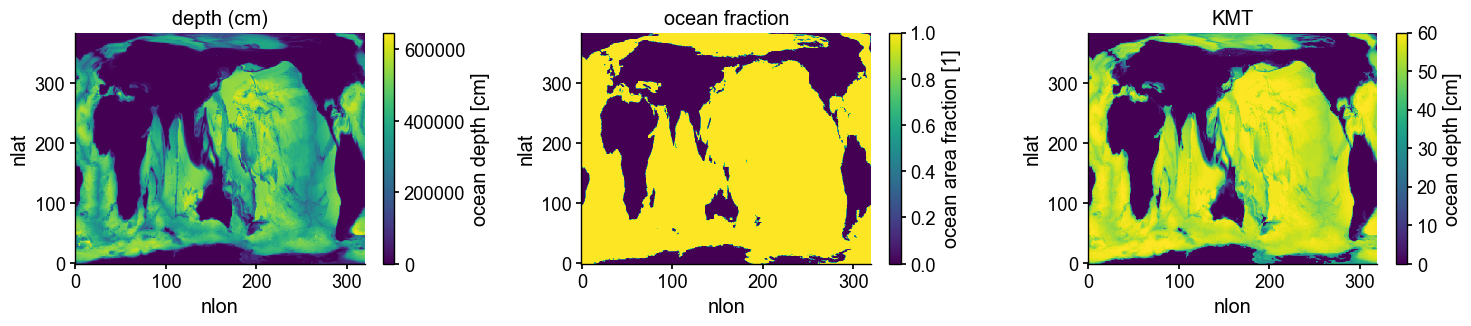

In [8]:
%%time

ds_topo = remap_topo(
    ds_topo_raw,
    ds_pop_grid.rename({'TLAT': 'lat', 'TLONG': 'lon'}),
    method='conservative'
)

# Depth to KMT: digitize returns the number of level centers at or above the
# cell's depth, so anything above sea level gets 0
ds_topo['KMT'] = xr.apply_ufunc(
    np.digitize, ds_topo.topo,
    kwargs={'bins': ds_pop_grid.z_t.values}).astype('int32')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ds_topo.topo.plot(ax=ax[0])
ds_topo.ofrac.plot(ax=ax[1])
ds_topo.KMT.plot(ax=ax[2])
ax[0].set_title("depth (cm)")
ax[1].set_title("ocean fraction")
ax[2].set_title("KMT")
fig.tight_layout()

ds_topo

## 5. Clean up KMT

- Southern and northern boundary rows must be land (POP needs a wall there)
- Use ocean area fraction of 0.5 to set the coastline
- Remove isolated points (a B-grid cannot move water through them)
- Remove ocean not connected to the main basin
- Manual edits where needed
- Cells with fewer than 3 levels are deepened

In [9]:
kmt0 = ds_topo.KMT.drop_vars(['ULAT', 'ULONG']).copy(deep=True)

[ 0  1  2  4  7 10 12 13 14 21 22 23 24 25 26 27 29 30 31 32 33 34 35 36
 37 38 39 40 42 43]
[ 0  1  2  3  4  5  6  7  9 10 12 17 18 20 21 24 28 29 31 32 33 34 35 36
 37 38 39 40 41 42 43 44 45 46 47 48 49]


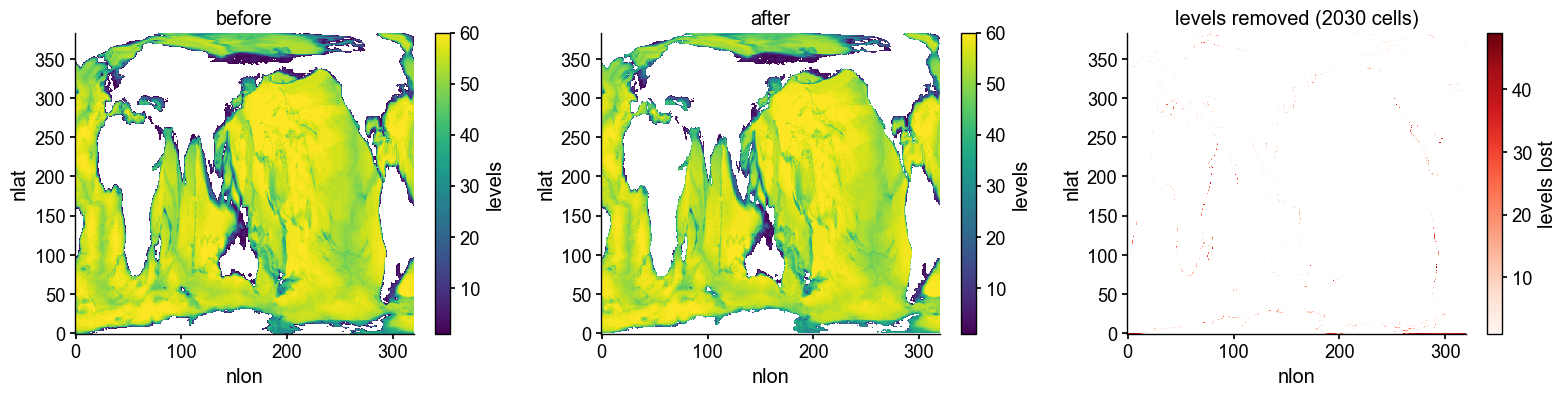

In [10]:
kmt_bnd_lmt = kmt0.copy(deep=True)

# Check the boundary rows
print(np.unique(kmt0.isel(nlat=0)))
print(np.unique(kmt0.isel(nlat=-1)))

# Southern/northern boundary must be land
kmt_bnd_lmt.loc[dict(nlat=0)] = 0
kmt_bnd_lmt.loc[dict(nlat=-1)] = 0

# A cell is ocean only if most of its area is ocean
kmt_bnd_lmt = kmt_bnd_lmt.where(ds_topo.ofrac.values >= 0.5, 0)

plot3(kmt0, kmt_bnd_lmt, "levels removed");

level 60: removed 448
level 60: removed 53
level 60: removed 3
level 60: removed 3
level 59: removed 582
level 59: removed 65
level 59: removed 6
level 58: removed 607
level 58: removed 57
level 58: removed 4
level 58: removed 1
level 57: removed 522
level 57: removed 67
level 57: removed 7
level 56: removed 562
level 56: removed 60
level 56: removed 8
level 56: removed 2
level 56: removed 1
level 56: removed 1
level 56: removed 1
level 55: removed 545
level 55: removed 64
level 55: removed 7
level 54: removed 461
level 54: removed 42
level 54: removed 7
level 53: removed 420
level 53: removed 54
level 53: removed 5
level 53: removed 2
level 52: removed 386
level 52: removed 35
level 52: removed 4
level 52: removed 1
level 51: removed 335
level 51: removed 22
level 50: removed 280
level 50: removed 25
level 50: removed 1
level 49: removed 225
level 49: removed 16
level 49: removed 2
level 48: removed 221
level 48: removed 15
level 48: removed 1
level 47: removed 201
level 47: removed 2

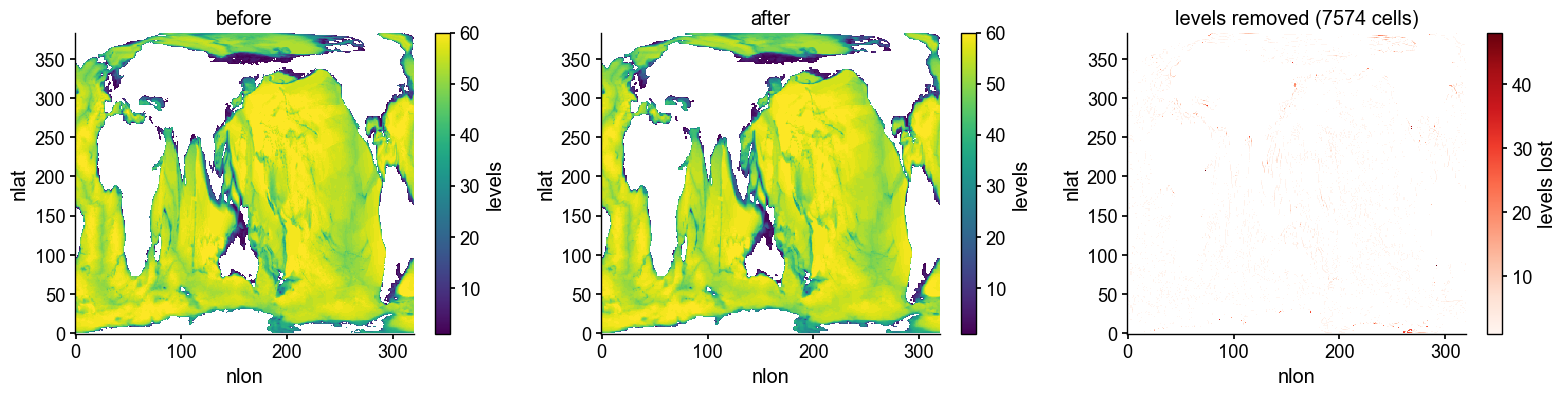

In [11]:
# Remove isolated ocean points
kmt_rm_pnts = remove_isolated_points(kmt_bnd_lmt)

plot3(kmt_bnd_lmt, kmt_rm_pnts, "levels removed");

seed: lon_idx=213, lat_idx=73, TLAT=-40.22, TLONG=200.19
kept 84402 of 84782 ocean cells


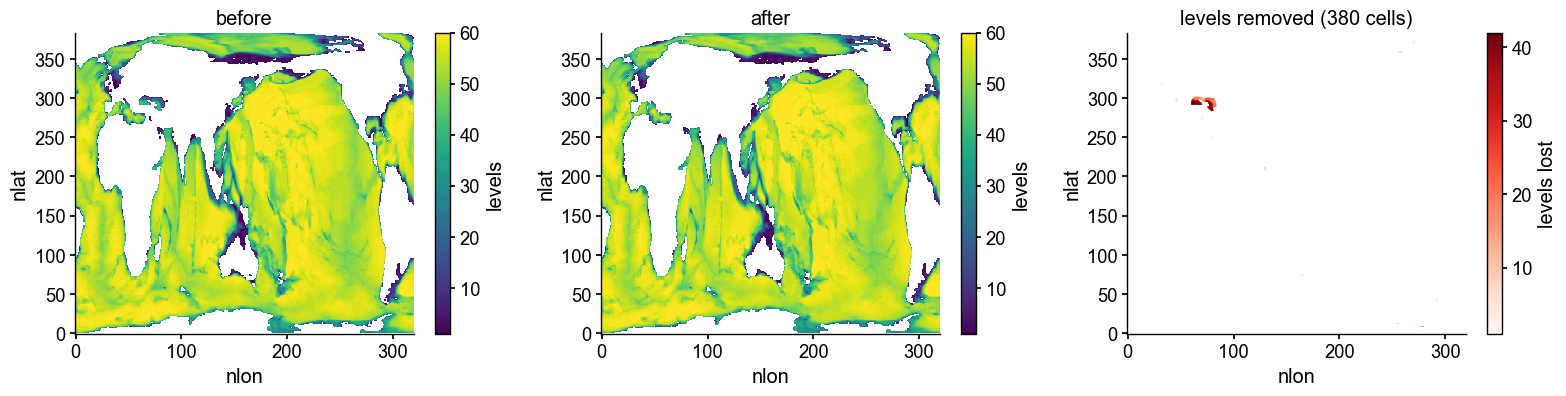

In [12]:
# seed the flood fill from a point unambiguously in the main basin (South Pacific)
dist = np.hypot(ds_pop_grid.TLAT.values - (-40.0),
                (ds_pop_grid.TLONG.values - 200.0 + 180.0) % 360.0 - 180.0)
lat_idx, lon_idx = np.unravel_index(np.argmin(dist), dist.shape)
lon_idx, lat_idx = int(lon_idx), int(lat_idx)
print(f"seed: lon_idx={lon_idx}, lat_idx={lat_idx}, "
      f"TLAT={ds_pop_grid.TLAT.values[lat_idx, lon_idx]:.2f}, "
      f"TLONG={ds_pop_grid.TLONG.values[lat_idx, lon_idx]:.2f}")

kmt_rm_bay = remove_disconnected_bays(kmt_rm_pnts, lon_idx, lat_idx)

plot3(kmt_rm_pnts, kmt_rm_bay, "levels removed");

The removed ocean is dominated by the **Paratethys** (~40N, 42E), plus a few small enclosed seas and
sub-grid coastal ponds. The cell below verifies that the Paratethys is already enclosed in the raw
0.25° reconstruction, i.e. its removal is intended and not an artifact of the remapping: POP cannot
sustain an isolated basin (it would need the marginal-sea balancing instead).

In [13]:
# summarize what remove_disconnected_bays dropped
removed = (np.asarray(kmt_rm_pnts) > 0) & (np.asarray(kmt_rm_bay) == 0)
lab, nblob = ndimage.label(removed)
sizes = ndimage.sum(removed, lab, range(1, nblob + 1))
print(f"removed {int(removed.sum())} cells in {nblob} blobs; largest:")
for b in np.argsort(sizes)[::-1][:8]:
    jj, ii = np.where(lab == b + 1)
    print(f"  {int(sizes[b]):5d} cells around "
          f"({ds_pop_grid.TLAT.values[jj, ii].mean():.1f}N, "
          f"{ds_pop_grid.TLONG.values[jj, ii].mean():.1f}E)")

# the Paratethys is enclosed already in the raw 0.25 deg reconstruction
ocn_raw = (ds_topo_raw.topo.values < 0)
lab_raw, _ = ndimage.label(ocn_raw)
for j in range(ocn_raw.shape[0]):   # merge labels across the cyclic seam
    a, b = lab_raw[j, 0], lab_raw[j, -1]
    if a > 0 and b > 0 and a != b:
        lab_raw[lab_raw == b] = a
ids, counts = np.unique(lab_raw[lab_raw > 0], return_counts=True)
main = ids[np.argmax(counts)]
jsel = (ds_topo_raw.lat.values > 38) & (ds_topo_raw.lat.values < 52)
isel = (ds_topo_raw.lon.values > 28) & (ds_topo_raw.lon.values < 58)
paratethys_labels = set(np.unique(lab_raw[np.ix_(jsel, isel)])) - {0}
print(f"\nParatethys connected to the main ocean in the raw data? "
      f"{main in paratethys_labels}")

removed 380 cells in 13 blobs; largest:
    289 cells around (40.3N, 41.8E)
     15 cells around (6.3N, 105.9E)
     12 cells around (29.0N, 39.9E)
     10 cells around (69.4N, 267.1E)
      9 cells around (48.0N, 354.8E)
      8 cells around (-39.8N, 146.0E)
      8 cells around (17.9N, 49.9E)
      7 cells around (39.9N, 11.3E)

Paratethys connected to the main ocean in the raw data? False


lon 204, lat 7: 0 -> 21  (wet neighbors [13, 18, 32])
lon 203, lat 8: 0 -> 21  (wet neighbors [18, 20, 24])
lon 204, lat 8: 0 -> 23  (wet neighbors [21, 21, 24, 26])
lon 72, lat 14: 0 -> 35  (wet neighbors [17, 43, 46])
lon 73, lat 14: 0 -> 26  (wet neighbors [8, 23, 35, 36])
lon 106, lat 49: 0 -> 27  (wet neighbors [23, 24, 35])
lon 106, lat 50: 0 -> 23  (wet neighbors [18, 24, 27])
lon 107, lat 50: 0 -> 24  (wet neighbors [16, 23, 24, 32])
lon 198, lat 69: 0 -> 30  (wet neighbors [4, 29, 38, 47])
lon 295, lat 243: 0 -> 45  (wet neighbors [38, 44, 47, 52])
lon 295, lat 247: 0 -> 36  (wet neighbors [22, 37, 43, 43])
lon 296, lat 248: 0 -> 36  (wet neighbors [29, 37, 43])
lon 297, lat 248: 0 -> 44  (wet neighbors [36, 42, 48, 52])
lon 290, lat 256: 0 -> 30  (wet neighbors [9, 35, 46])
lon 290, lat 257: 0 -> 19  (wet neighbors [7, 9, 30, 30])
lon 43, lat 287: 0 -> 37  (wet neighbors [35, 37, 38])
lon 43, lat 288: 0 -> 39  (wet neighbors [35, 37, 45])
lon 43, lat 289: 0 -> 34  (wet neighb

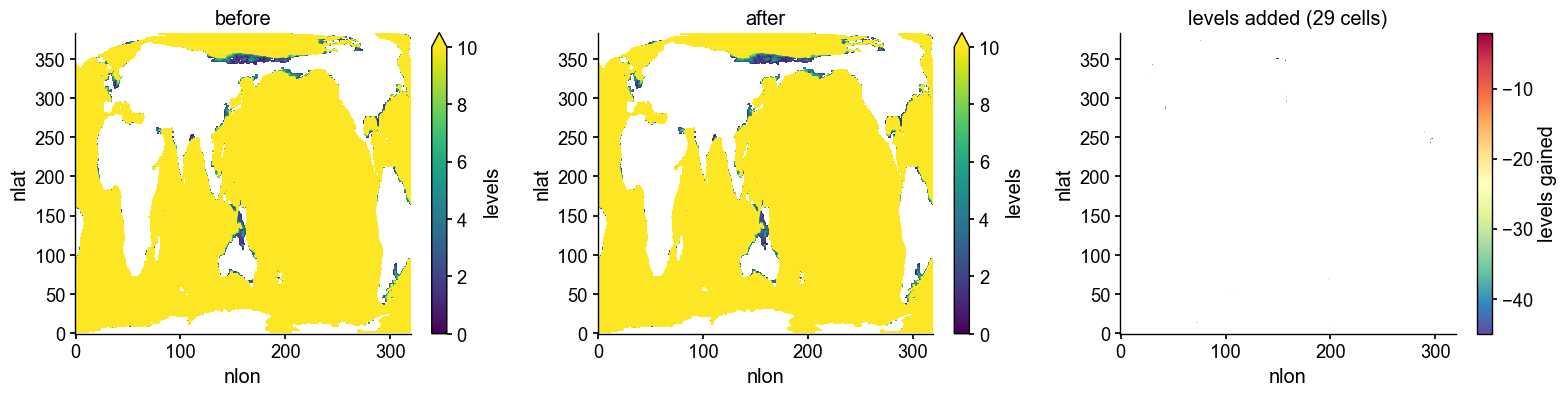

In [14]:
# Remove islands / peninsula
kmt_islands = fill_small_islands(kmt_rm_bay, max_size=3)

plot3(kmt_rm_bay, kmt_islands, "levels added", clim=(0, 10),
      cmap_change="Spectral_r", label_change="levels gained");

### Manual edits

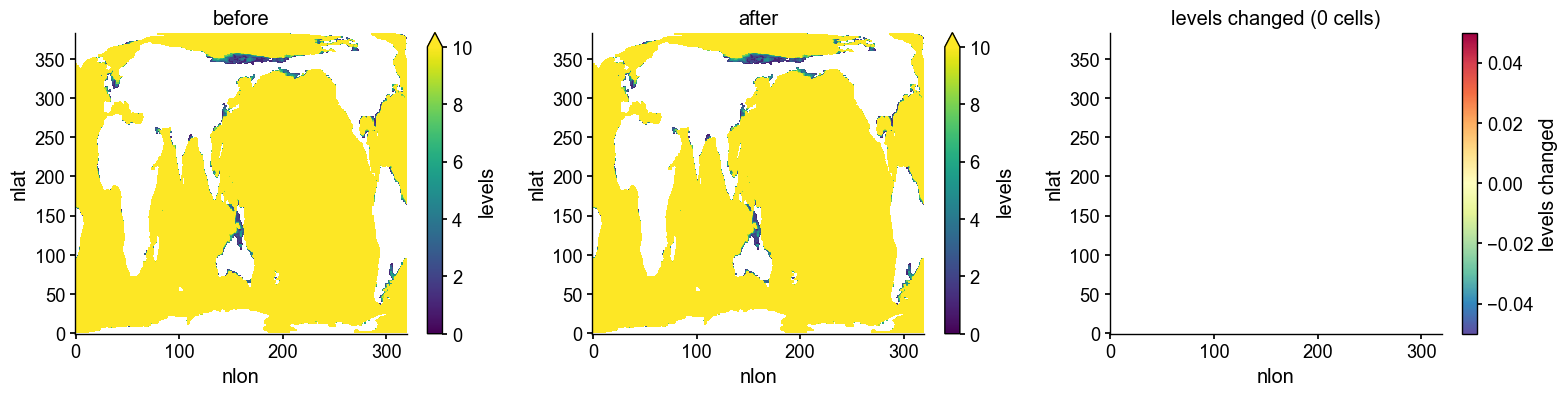

In [15]:
kmt_manual = kmt_islands.copy(deep=True)

# No manual carving is needed for this reconstruction:
# - all major gateways (Bering, Gibraltar, Central American Seaway, Drake,
#   Fram, Indonesian Throughflow) are open and at least two T-cells wide,
#   so they survive the B-grid connectivity checks above
# - the inland seas removed above (Paratethys etc.) are enclosed in the raw
#   reconstruction, so they are meant to be gone

plot3(kmt_islands, kmt_manual, "levels changed", clim=(0, 10),
      cmap_change="Spectral_r", label_change="levels changed");

level 45: removed 1
level 39: removed 1
level 38: removed 1
level 34: removed 1
level 33: removed 1
level 32: removed 1
level 29: removed 1
level 28: removed 1
level 27: removed 2
level 26: removed 2
level 25: removed 2
level 24: removed 1
level 22: removed 1
level 21: removed 3
level 20: removed 2
level 19: removed 2
level 18: removed 1
level 17: removed 1
level 16: removed 1
level 15: removed 1
level 14: removed 1
level 13: removed 1
level 12: removed 1
level 11: removed 1
level 10: removed 1
level 9: removed 1
level 8: removed 1
level 7: removed 1
level 2: removed 2
level 2: removed 1
kept 84431 of 84431 ocean cells


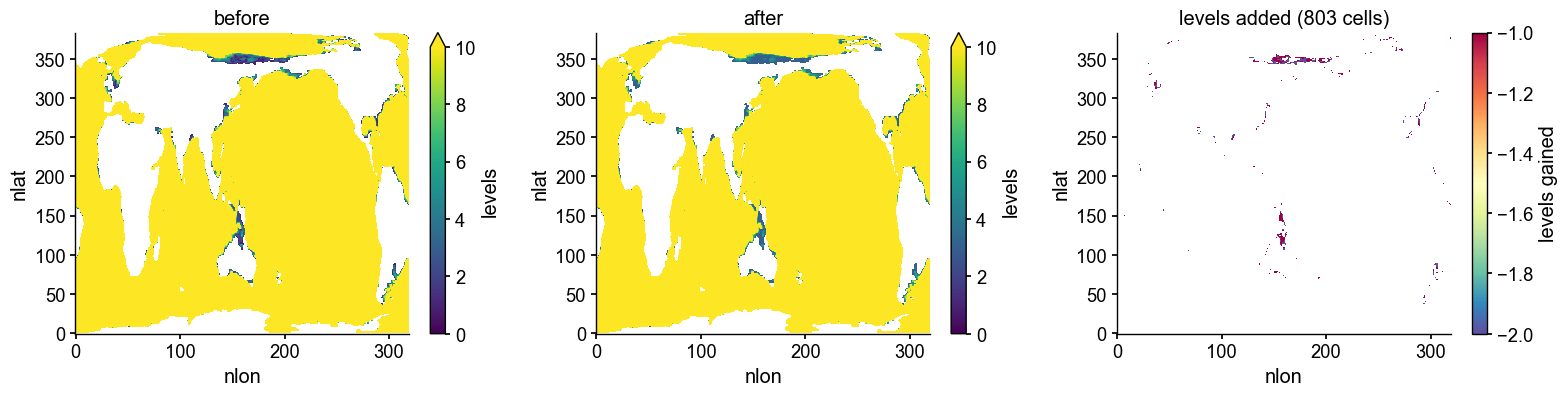

In [16]:
# Remove isolated points again
kmt_manual = remove_isolated_points(kmt_manual)
kmt_manual = remove_disconnected_bays(kmt_manual, lon_idx, lat_idx)

# POP needs at least 3 levels; deepen rather than remove
too_shallow = (kmt_manual > 0) & (kmt_manual < 3)
kmt_deepen = xr.where(too_shallow, 3, kmt_manual).astype('int32')

plot3(kmt_manual, kmt_deepen, "levels added", clim=(0, 10),
      cmap_change="Spectral_r", label_change="levels gained");

### Check the final KMT

- Compare ocean area and volume against the raw field and the preindustrial gx1v6

In [17]:
kmt_final = kmt_deepen.copy(deep=True)

assert int(kmt_final.max()) <= nlev
assert (kmt_final.isel(nlat=0) == 0).all() and (kmt_final.isel(nlat=-1) == 0).all()
assert int(kmt_final.min()) == 0 and not ((kmt_final > 0) & (kmt_final < 3)).any()


R = 6.37122e6
z_w_bot = ds_pop_grid.z_w_bot.values


def kmt_to_depth(kmt):
    """Bottom depth (cm) of the deepest wet level, 0 where land."""
    nlev = int(kmt.max())
    d = np.where(kmt > 0, z_w_bot[np.clip(kmt.values, 1, nlev) - 1], 0.0)
    return xr.DataArray(d, dims=kmt.dims, coords=kmt.coords)


# raw source grid: cell areas from lat bounds on a regular lat-lon grid
lat_raw = ds_topo_raw.lat.values
lon_raw = ds_topo_raw.lon.values
dlon = np.deg2rad(np.abs(lon_raw[1] - lon_raw[0]))
dlat = np.abs(lat_raw[1] - lat_raw[0])
lat_s = np.deg2rad(np.clip(lat_raw - dlat / 2, -90, 90))
lat_n = np.deg2rad(np.clip(lat_raw + dlat / 2, -90, 90))
area_1d = R**2 * dlon * (np.sin(lat_n) - np.sin(lat_s))
area_raw = xr.DataArray(np.repeat(area_1d[:, None], lon_raw.size, axis=1),
                        dims=ds_topo_raw.topo.dims, coords=ds_topo_raw.topo.coords)
wet_raw = ds_topo_raw.topo < 0                                    # negative elevation = ocean
area_raw_ocn = float(area_raw.where(wet_raw).sum())               # m2
vol_raw_ocn = float((area_raw * -ds_topo_raw.topo).where(wet_raw).sum())     # m3

# Miocene POP grid, from TAREA (cm2) and the level bottoms
wet = kmt_final > 0
depth = kmt_to_depth(kmt_final)
area_pop_ocn = float(ds_pop_grid.TAREA.where(wet).sum()) * 1e-4  # cm2 -> m2
vol_pop_ocn = float((ds_pop_grid.TAREA * depth).sum()) * 1e-6    # cm3 -> m3

# preindustrial gx1v6 on the same grid, for reference
ds_pi = xr.open_dataset(pop_grid_pre)
wet_pi = ds_pi.KMT > 0
depth_pi = kmt_to_depth(ds_pi.KMT)
area_pi = float(ds_pi.TAREA.where(wet_pi).sum()) * 1e-4
vol_pi = float((ds_pi.TAREA * depth_pi).sum()) * 1e-6

print("                       raw           pop        PI(gx1v6)     pop vs PI")
print("ocean area (1e6 km2) %9.2f     %9.2f     %9.2f     %+6.1f %%"
      % (area_raw_ocn / 1e12, area_pop_ocn / 1e12, area_pi / 1e12,
         (area_pop_ocn / area_pi - 1) * 100))
print("ocean vol  (1e6 km3) %9.2f     %9.2f     %9.2f     %+6.1f %%"
      % (vol_raw_ocn / 1e15, vol_pop_ocn / 1e15, vol_pi / 1e15,
         (vol_pop_ocn / vol_pi - 1) * 100))
print("mean depth (m)       %9.0f     %9.0f     %9.0f     %+6.1f %%"
      % (vol_raw_ocn / area_raw_ocn, vol_pop_ocn / area_pop_ocn, vol_pi / area_pi,
         ((vol_pop_ocn / area_pop_ocn) / (vol_pi / area_pi) - 1) * 100))
print("ocean cells          %9s     %9d     %9d"
      % ("-", int(wet.sum()), int(wet_pi.sum())))

                       raw           pop        PI(gx1v6)     pop vs PI
ocean area (1e6 km2)    359.36        355.72        361.14       -1.5 %
ocean vol  (1e6 km3)   1346.41       1332.36       1325.14       +0.5 %
mean depth (m)            3747          3746          3669       +2.1 %
ocean cells                  -         84431         86212


### Check the key ocean gateways

All the major gateways expected at 15 Ma are open: the Bering Strait, Gibraltar, the Central American
Seaway, Drake Passage, Fram Strait, and the Indonesian Throughflow.

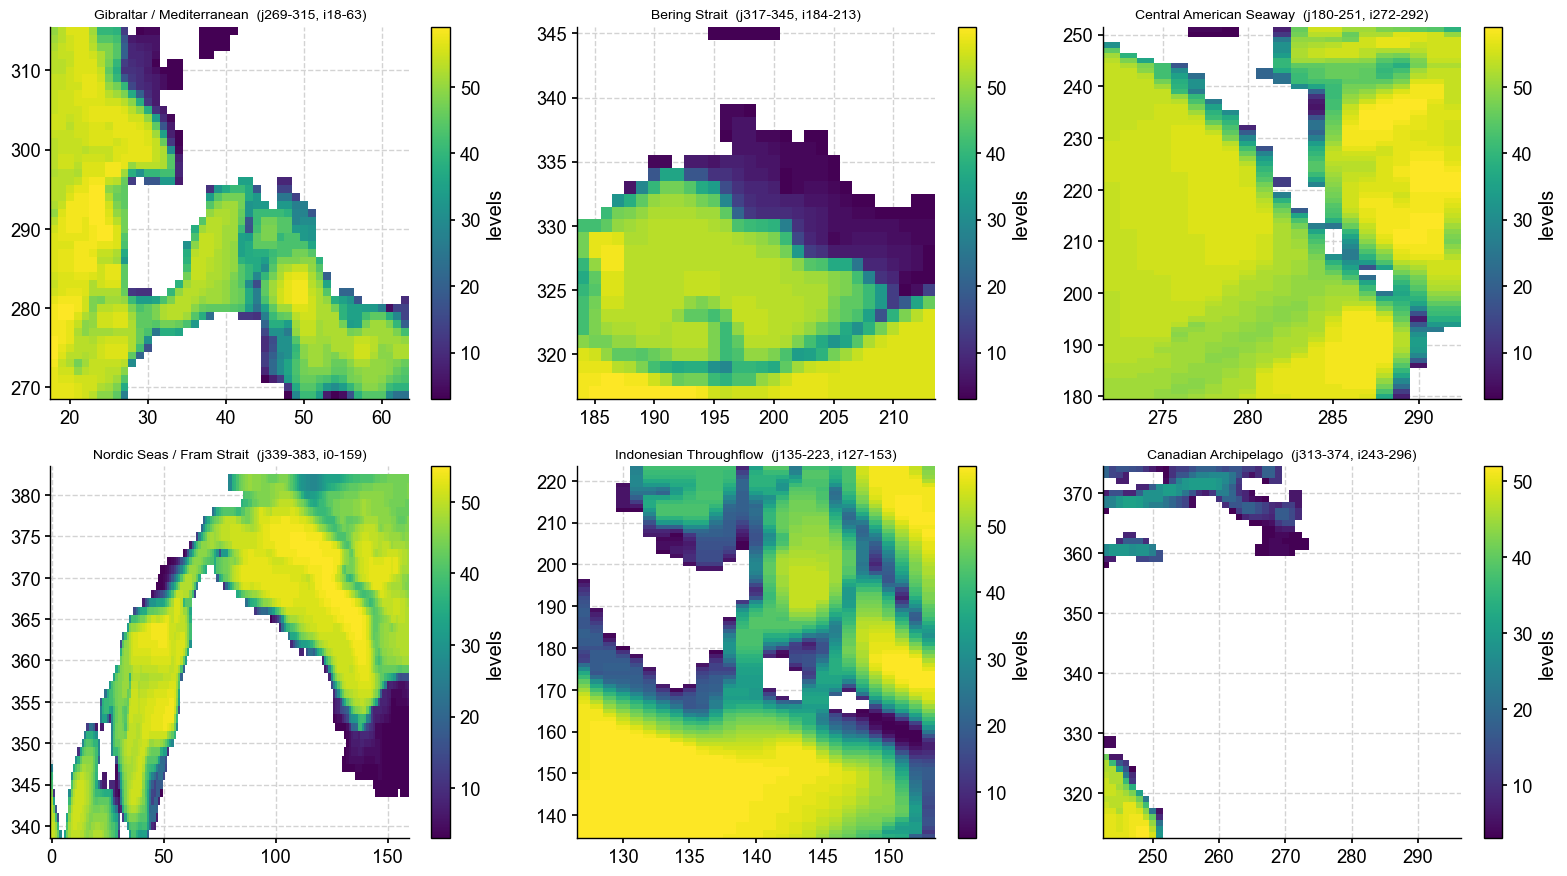

In [18]:
tl, tn = ds_pop_grid.TLAT.values, ds_pop_grid.TLONG.values
kf = np.asarray(kmt_final)


def index_window(lat0, lon0, dlat, dlon):
    """(j0, j1, i0, i1) covering the lat/lon box (assumes it avoids the i seam)."""
    sel = (np.abs(tl - lat0) < dlat) & (np.abs((tn - lon0 + 180) % 360 - 180) < dlon)
    jj, ii = np.where(sel)
    return jj.min(), jj.max(), ii.min(), ii.max()


fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, box) in zip(axs.flat, [
        ('Gibraltar / Mediterranean', (36, 5, 10, 25)),
        ('Bering Strait', (65, 190, 8, 15)),
        ('Central American Seaway', (8, 278, 10, 12)),
        ('Nordic Seas / Fram Strait', (72, 350, 12, 30)),
        ('Indonesian Throughflow', (-2, 118, 12, 15)),
        ('Canadian Archipelago', (60, 275, 12, 20))]):
    j0, j1, i0, i1 = index_window(*box)
    sub = np.where(kf[j0:j1 + 1, i0:i1 + 1] > 0, kf[j0:j1 + 1, i0:i1 + 1], np.nan)
    im = ax.pcolormesh(np.arange(i0, i1 + 1), np.arange(j0, j1 + 1), sub, cmap='viridis')
    ax.set_title(f"{name}  (j{j0}-{j1}, i{i0}-{i1})", fontsize=10)
    plt.colorbar(im, ax=ax, label='levels')
fig.tight_layout()

## 6. Region mask

- POP's REGION_MASK carries basin indices used for diagnostics and for the marginal-sea parameterizations.
- Paleo basins, not POP's standard numbering (following the Eocene recipe): 1 = global ocean, 2 = N Pacific, 3 = Arctic
- Because the Central American Seaway is open at 15 Ma, the N Pacific flood fill needs an explicit wall there
  (in addition to the equator and a row south of the Bering Strait); the ocean cells inside a wall stay region 1.

j_eq = 186
(array([0, 1, 2, 3], dtype=int32), array([38449, 60057, 18402,  5972]))


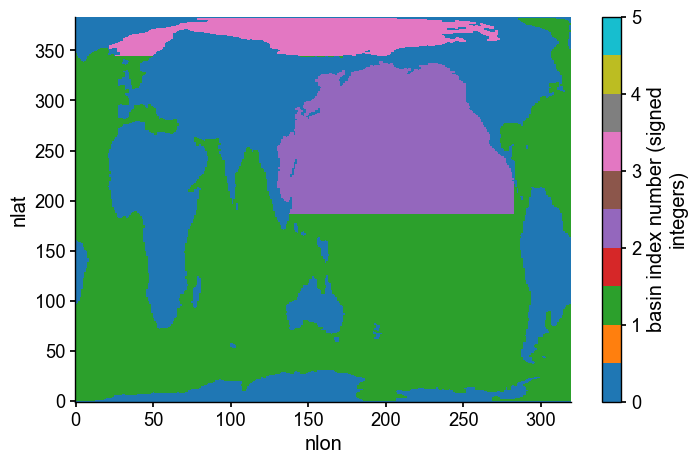

In [19]:
ocean = kmt_final.values > 0

j_eq = int(np.abs(ds_pop_grid.TLAT.values[:, 200]).argmin())   # equator row
j_bering = 344            # row just south of the Bering Strait opening (j=345)
wall_eq = (j_eq, j_eq, 0, 319)
wall_bering = (j_bering, j_bering, 0, 319)
wall_cas = (j_eq, 280, 283, 294)   # Central American Seaway, open at 15 Ma
print(f"j_eq = {j_eq}")

# seeds: mid N Pacific (~40N, 179E) and near the North Pole
npac   = flood_basin(ocean, seed=(289, 194), walls=[wall_eq, wall_bering, wall_cas])
arctic = flood_basin(ocean, seed=(370, 146), walls=[wall_bering])

mask = np.where(ocean, 1, 0).astype("int32")
mask[npac] = 2
mask[arctic] = 3

rmask_final = xr.DataArray(mask, dims=kmt_final.dims, coords=kmt_final.coords,
                           name="REGION_MASK").astype("int32")
rmask_final.attrs = {
    "long_name": "basin index number (signed integers)",
    "basins": "1 = global ocean, 2 = N Pacific, 3 = Arctic; "
              "paleo basins, not POP's standard numbering",
}
print(np.unique(mask, return_counts=True))

fig, ax = plt.subplots(figsize=(8, 5))
rmask_final.drop_vars(['lat', 'lon'], errors='ignore').plot(
    ax=ax, cmap="tab10", vmin=0, vmax=5)

## 7. Save

- POP reads flat big-endian int32 binaries with no header, `nlat*nlon` values in C order (longitude varying fastest).
- The netCDF and SCRIP files are for inspection and for downstream tools (`gen_domain`, mapping file generation).

In [20]:
work_dir = Path('../output')
case_string = f"gx1v6_{case}"

# binary files read by POP (big-endian int32)
pop_topo = work_dir / f"topography_{case_string}.{today}.ieeei4"
pop_mask = work_dir / f"region_mask_{case_string}.{today}.ieeei4"

# netCDF copy, not used by POP itself
pop_netcdf = work_dir / f"pop_grid_kmt_rmask_{case_string}.{today}.nc"

# SCRIP file
pop_scrip = work_dir / f"pop_scrip_{case_string}.{today}.nc"

np.asarray(kmt_final).astype('>i4').tofile(pop_topo)
np.asarray(rmask_final).astype('>i4').tofile(pop_mask)

for p in [pop_topo, pop_mask]:
    print(f"Saved: {p}  {p.stat().st_size} bytes")

Saved: ../output/topography_gx1v6_MioMIP2_Phase2_CORE.260903.ieeei4  491520 bytes
Saved: ../output/region_mask_gx1v6_MioMIP2_Phase2_CORE.260903.ieeei4  491520 bytes


In [21]:
# NetCDF file
dims = ('nlat', 'nlon')
ds_out = ds_pop_grid.drop_vars(['lat_b', 'lon_b']).copy()

ds_out['Depth'] = (dims, kmt_to_depth(kmt_final).values)
ds_out['Depth'].attrs = {'long_name': 'ocean depth', 'units': 'cm'}
ds_out['KMT'] = (dims, np.asarray(kmt_final))
ds_out['REGION_MASK'] = (dims, np.asarray(rmask_final))
ds_out['REGION_MASK'].attrs = rmask_final.attrs

ds_out.attrs = {
    'title': f'gx1v6 Miocene POP grid, {case} bathymetry (15 Ma)',
    'source_topography': str(Path(raw_topo_fpath).resolve()),
    'source_grid': str(pop_grid),
    'author': 'Feng Zhu (fengzhu@ucar.edu)',
    'created_by': 'ocn-bc-kmt.ipynb',
    'created_on': time.strftime('%Y-%m-%d'),
}
ds_out.to_netcdf(pop_netcdf)
print("written:", pop_netcdf)
ds_out

written: ../output/pop_grid_kmt_rmask_gx1v6_MioMIP2_Phase2_CORE.260903.nc


<xarray.Dataset> Size: 11MB
Dimensions:      (nlat: 384, nlon: 320, z_t: 60, z_w_bot: 60)
Coordinates:
    TLAT         (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... 72.19 72.19
    TLONG        (nlat, nlon) float64 983kB 320.6 321.7 322.8 ... 319.4 319.8
    ULAT         (nlat, nlon) float64 983kB -78.95 -78.95 -78.95 ... 72.41 72.41
    ULONG        (nlat, nlon) float64 983kB 321.1 322.3 323.4 ... 319.6 320.0
  * z_t          (z_t) float64 480B 500.0 1.5e+03 ... 5.125e+05 5.375e+05
    dz           (z_t) float64 480B 1e+03 1e+03 1e+03 ... 2.5e+04 2.5e+04
  * z_w_bot      (z_w_bot) float64 480B 1e+03 2e+03 3e+03 ... 5.25e+05 5.5e+05
Dimensions without coordinates: nlat, nlon
Data variables:
    HTN          (nlat, nlon) float64 983kB 2.397e+06 2.397e+06 ... 1.391e+06
    HTE          (nlat, nlon) float64 983kB 5.94e+06 5.94e+06 ... 5.046e+06
    DXT          (nlat, nlon) float64 983kB 2.397e+06 2.397e+06 ... 1.473e+06
    DYT          (nlat, nlon) float64 983kB 5.94e+06 5.94e+06 ... 5.046e+06
    TAREA        (nlat, nlon) float64 983kB 1.423e+13 1.423e+13 ... 7.432e+12
    Depth        (nlat, nlon) float64 983kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    KMT          (nlat, nlon) int32 492kB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
    REGION_MASK  (nlat, nlon) int32 492kB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
Attributes:
    title:              gx1v6 Miocene POP grid, MioMIP2_Phase2_CORE bathymetr...
    source_topography:  /glade/work/fengzhu/GitHub/paleowg-recipes/docsrc/Mio...
    source_grid:        /glade/p/cesmdata/inputdata/ocn/pop/gx1v6/grid/horiz_...
    author:             Feng Zhu (fengzhu@ucar.edu)
    created_by:         ocn-bc-kmt.ipynb
    created_on:         2026-09-03

In [22]:
# SCRIP file
ds_scrip = to_scrip(corner_lat, corner_lon, TLAT, TLONG, kmt_final,
                    TAREA=ds_pop_grid.TAREA, title=f"gx1v6 {case}")
ds_scrip.to_netcdf(pop_scrip)
print("written:", pop_scrip)

written: ../output/pop_scrip_gx1v6_MioMIP2_Phase2_CORE.260903.nc
